<a href="https://colab.research.google.com/github/MYunan17/PCVK-Genap-25-26/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 — Morfologi Citra
**Pengolahan Citra dan Visi Komputer** — Mochamad Yunan Helmy Affandi (TI-3A / 13)

Modul 9: Erosi, Dilasi, Opening, Closing, Top-hat, Black-hat, Skeleton, Thinning, dan Tugas Praktikum KTP.

## Langkah 1 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Langkah 2 — Import library, konfigurasi path, dan helper


In [ ]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

BASE = '/content/drive/MyDrive/PCVK'

def pick(*names):
    """Kembalikan path pertama yang ada di folder PCVK."""
    for n in names:
        p = os.path.join(BASE, n)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Tidak ada satupun dari: {names}')

IMG_PLAT   = pick('Images/plat nomer.jpg', 'plat nomer.jpg', 'KTMa.jpeg')
IMG_KITTEN = pick('Images/kitten01.jpg', 'kitten01.jpg', 'lena.jpeg')
IMG_LILY   = pick('Images/lily.jpg', 'lily.jpg', 'mandrill.tiff')
IMG_KTP    = pick('Images/ktp_fulan.jpg', 'ktp_fulan.jpg')

for k, v in {'PLAT': IMG_PLAT, 'KITTEN': IMG_KITTEN, 'LILY': IMG_LILY, 'KTP': IMG_KTP}.items():
    print(f'{k:7s}-> {v}')

def tampil(imgs, titles, size=4.5):
    """Tampilkan beberapa citra berdampingan (BGR otomatis dikonversi ke RGB)."""
    n = len(imgs)
    plt.figure(figsize=(size * n, size))
    for i, (im, t) in enumerate(zip(imgs, titles)):
        plt.subplot(1, n, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap='gray')
        plt.title(t); plt.xticks([]); plt.yticks([])
    plt.tight_layout(); plt.show()

PLAT   -> /content/drive/MyDrive/PCVK/KTMa.jpeg
KITTEN -> /content/drive/MyDrive/PCVK/lena.jpeg
LILY   -> /content/drive/MyDrive/PCVK/mandrill.tiff
KTP    -> /content/drive/MyDrive/PCVK/ktp_fulan.jpg


In [ ]:
def _jendela(F, SE, pad_value):
    h, w = SE.shape
    Fp = np.pad(F, ((h // 2, h // 2), (w // 2, w // 2)), mode='constant', constant_values=pad_value)
    return sliding_window_view(Fp, (h, w)), SE.astype(bool)

def dilasi_citra(F, SE):
    win, mask = _jendela(F, SE, 0)        # padding 0 = netral untuk MAX
    return win[..., mask].max(axis=-1).astype(np.uint8)

def erosi_citra(F, SE):
    win, mask = _jendela(F, SE, 255)      # padding 255 = netral untuk MIN
    return win[..., mask].min(axis=-1).astype(np.uint8)

def opening_citra(F, SE):
    return dilasi_citra(erosi_citra(F, SE), SE)   # A o B = (A erosi B) dilasi B

def closing_citra(F, SE):
    return erosi_citra(dilasi_citra(F, SE), SE)   # A . B = (A dilasi B) erosi B

# Versi loop seperti di modul (dipakai untuk verifikasi)
def dilasi_citra_loop(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    c = (w - 1) // 2
    for i in range(c, p - c):
        for j in range(c, q - c):
            temp = F[i - c:i + c + 1, j - c:j + c + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

# Uji kecil: hasil manual vs OpenCV harus identik
A = (np.random.rand(60, 80) > 0.7).astype(np.uint8) * 255
for nama, SE in {'square3': np.ones((3, 3), np.uint8),
                 'cross5': cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5)),
                 'rect3x5': np.ones((3, 5), np.uint8)}.items():
    print(f'{nama:8s} dilasi sama: {np.array_equal(dilasi_citra(A, SE), cv2.dilate(A, SE))} | '
          f'erosi sama: {np.array_equal(erosi_citra(A, SE), cv2.erode(A, SE))}')
inner = (slice(1, -1), slice(1, -1))
print('loop modul == vektor (bagian dalam):', np.array_equal(dilasi_citra_loop(A, 3)[inner], dilasi_citra(A, np.ones((3,3),np.uint8))[inner]))

square3  dilasi sama: True | erosi sama: True
cross5   dilasi sama: True | erosi sama: True
rect3x5  dilasi sama: True | erosi sama: True
loop modul == vektor (bagian dalam): True


## Langkah 3 — Dilasi tanpa library, SE Cross 3x3

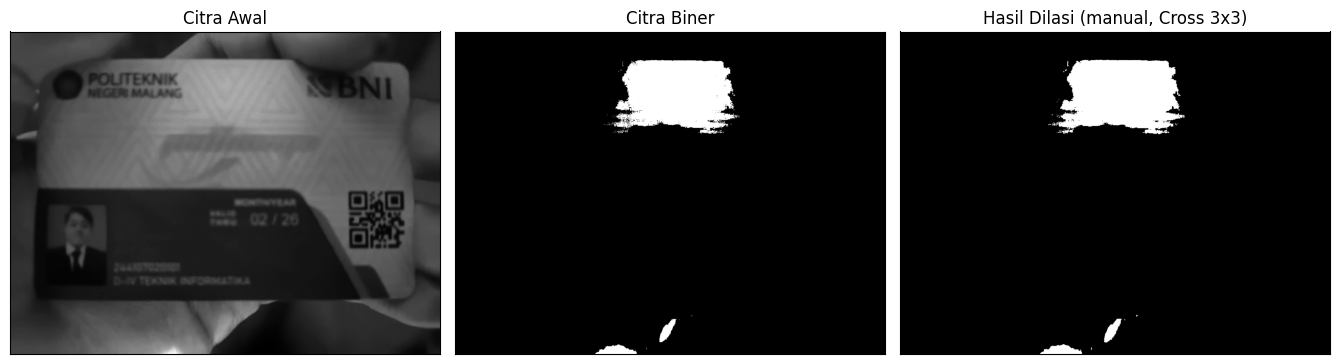

In [ ]:
SE_cross3 = np.array([[0, 1, 0],
                      [1, 1, 1],
                      [0, 1, 0]], dtype=np.uint8)

img_d = cv2.imread(IMG_PLAT, 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
imgD = dilasi_citra(thresh, SE_cross3)

tampil([img_d, thresh, imgD], ['Citra Awal', 'Citra Biner', 'Hasil Dilasi (manual, Cross 3x3)'])

## Langkah 4 — Dilasi dengan library OpenCV, SE Cross 3x3

[[0 1 0]
 [1 1 1]
 [0 1 0]]


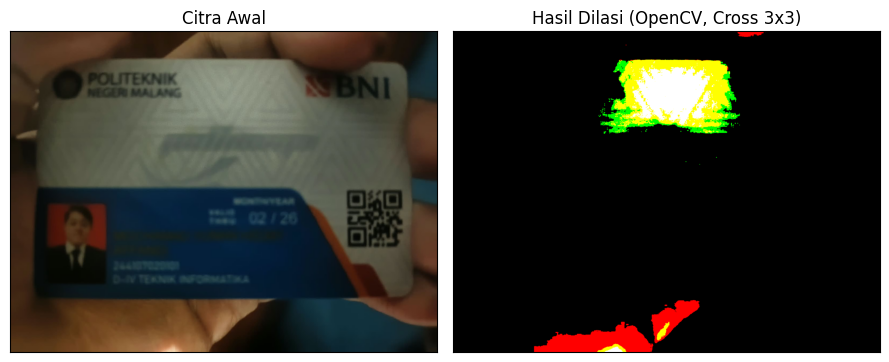

Manual (langkah 3) == OpenCV: True


In [ ]:
img = cv2.imread(IMG_PLAT)
ret, thresh_rgb = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
print(kernel)
dilasi = cv2.dilate(thresh_rgb, kernel, iterations=1)

tampil([img, dilasi], ['Citra Awal', 'Hasil Dilasi (OpenCV, Cross 3x3)'])
print('Manual (langkah 3) == OpenCV:', np.array_equal(imgD, cv2.dilate(thresh, kernel)))

## Langkah 5 — Erosi tanpa library, SE Square 5x5

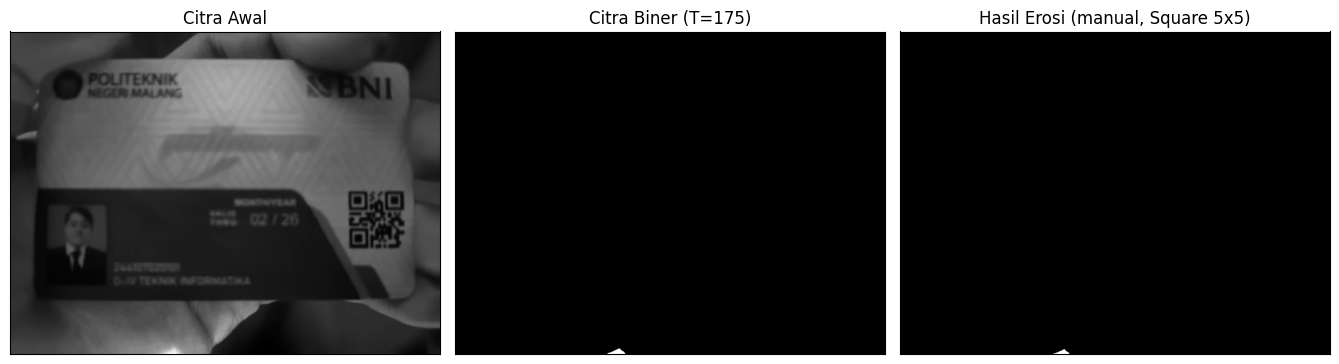

In [ ]:
img_e = cv2.imread(IMG_PLAT, 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)
SE_sq5 = np.ones((5, 5), dtype=np.uint8)
imgE = erosi_citra(thresh1, SE_sq5)

tampil([img_e, thresh1, imgE], ['Citra Awal', 'Citra Biner (T=175)', 'Hasil Erosi (manual, Square 5x5)'])

## Langkah 6 — Erosi dengan library OpenCV, SE Square 5x5

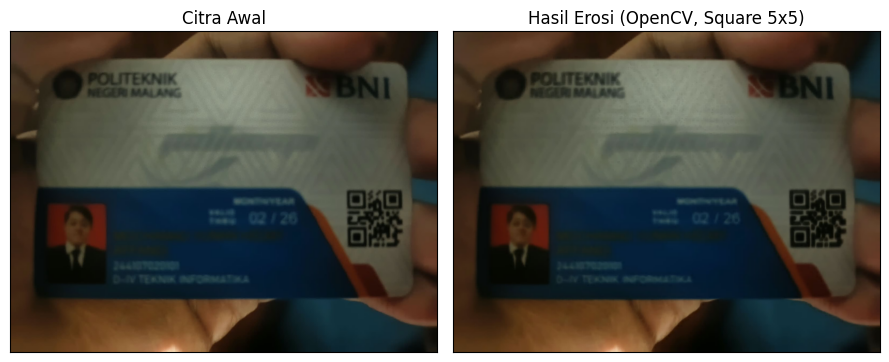

Manual (langkah 5) == OpenCV: True


In [ ]:
img = cv2.imread(IMG_PLAT)
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

tampil([img, erosion], ['Citra Awal', 'Hasil Erosi (OpenCV, Square 5x5)'])
print('Manual (langkah 5) == OpenCV:', np.array_equal(imgE, cv2.erode(thresh1, kernel)))

## Langkah 7 — Opening, SE Square 3x3 (tanpa & dengan library)

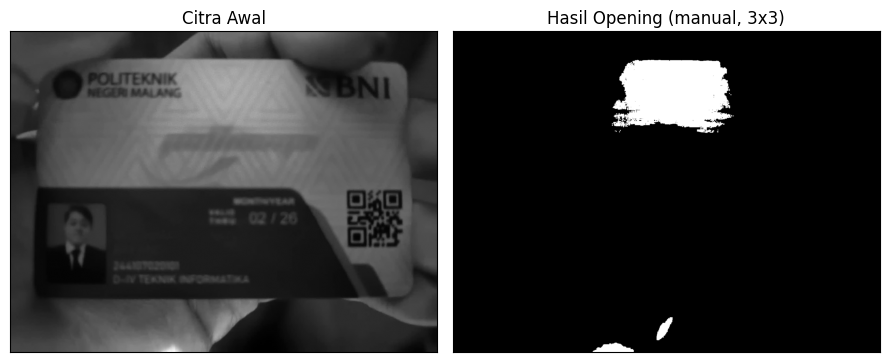

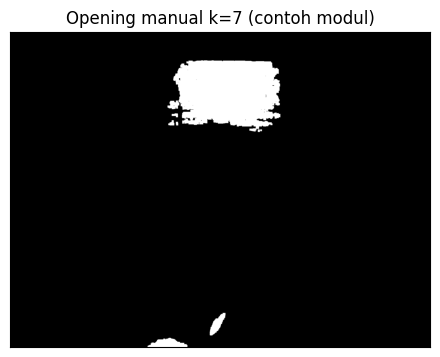

In [ ]:
# Tanpa library morphology
img_o = cv2.imread(IMG_PLAT, 0)
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)
SE_sq3 = np.ones((3, 3), np.uint8)
imgO = opening_citra(thresho, SE_sq3)
tampil([img_o, imgO], ['Citra Awal', 'Hasil Opening (manual, 3x3)'])

# Modul juga mencontohkan k=7: opening dengan SE besar menghapus hampir semua objek tipis
imgO7 = opening_citra(thresho, np.ones((7, 7), np.uint8))
tampil([imgO7], ['Opening manual k=7 (contoh modul)'])

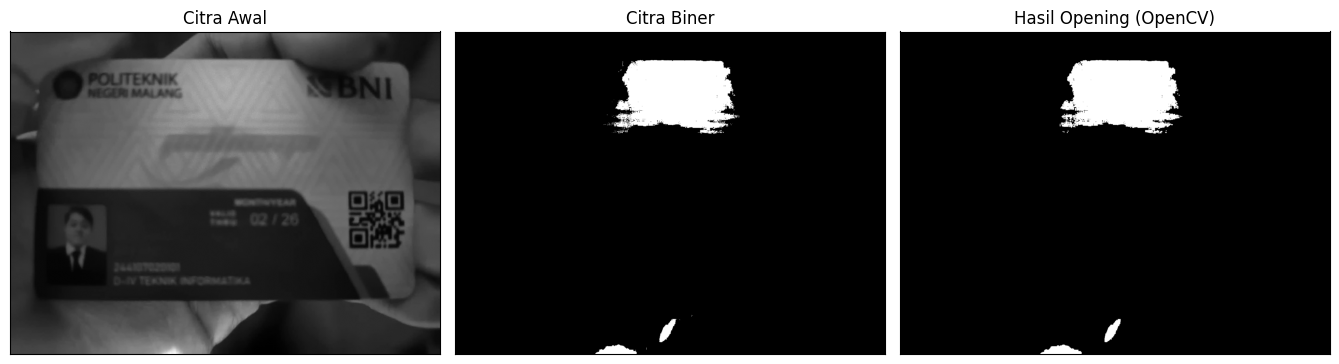

Manual == OpenCV: True


In [ ]:
# Dengan library morphology
img = cv2.imread(IMG_PLAT, 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

tampil([img, thresh, openn], ['Citra Awal', 'Citra Biner', 'Hasil Opening (OpenCV)'])
print('Manual == OpenCV:', np.array_equal(imgO, openn))

## Langkah 8 — Closing, SE Square 3x3 (tanpa & dengan library)

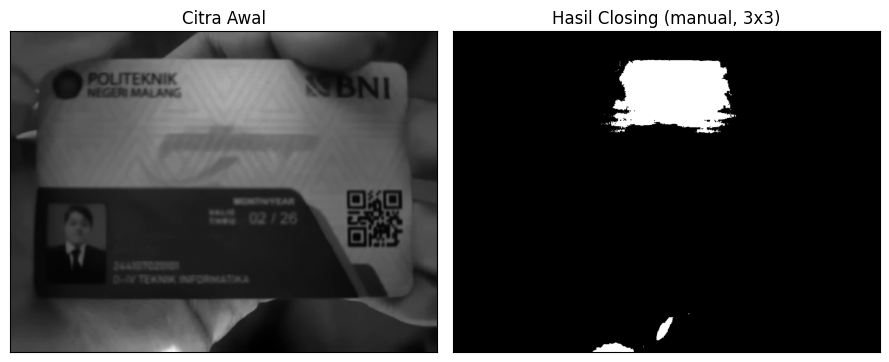

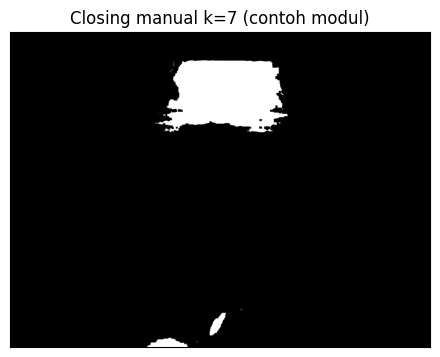

In [ ]:
# Tanpa library morphology
img_c = cv2.imread(IMG_PLAT, 0)
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)
imgC = closing_citra(threshc, SE_sq3)
tampil([img_c, imgC], ['Citra Awal', 'Hasil Closing (manual, 3x3)'])

imgC7 = closing_citra(threshc, np.ones((7, 7), np.uint8))
tampil([imgC7], ['Closing manual k=7 (contoh modul)'])

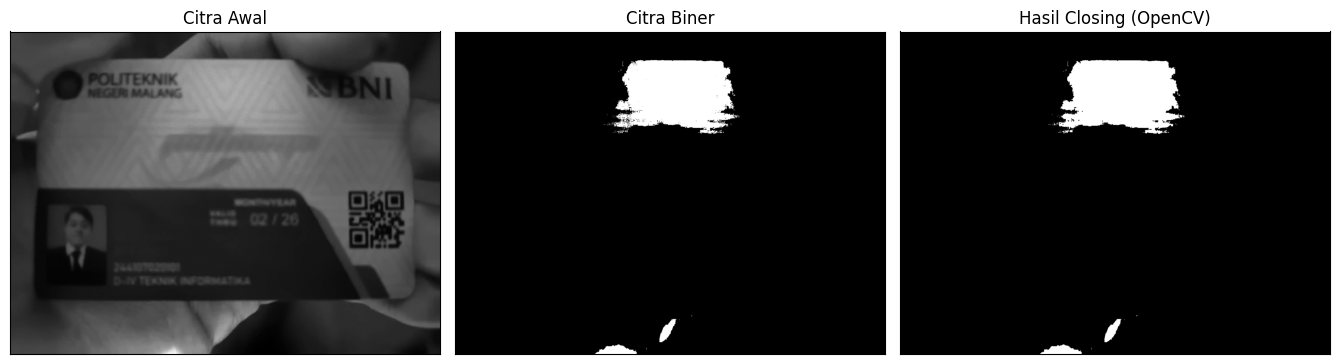

Manual == OpenCV: True


In [ ]:
# Dengan library morphology
img = cv2.imread(IMG_PLAT, 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

tampil([img, thresh, closs], ['Citra Awal', 'Citra Biner', 'Hasil Closing (OpenCV)'])
print('Manual == OpenCV:', np.array_equal(imgC, closs))

## Langkah 9 — Dilasi dengan SE Cross 3x3 dan 5x5

SE = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
SE = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


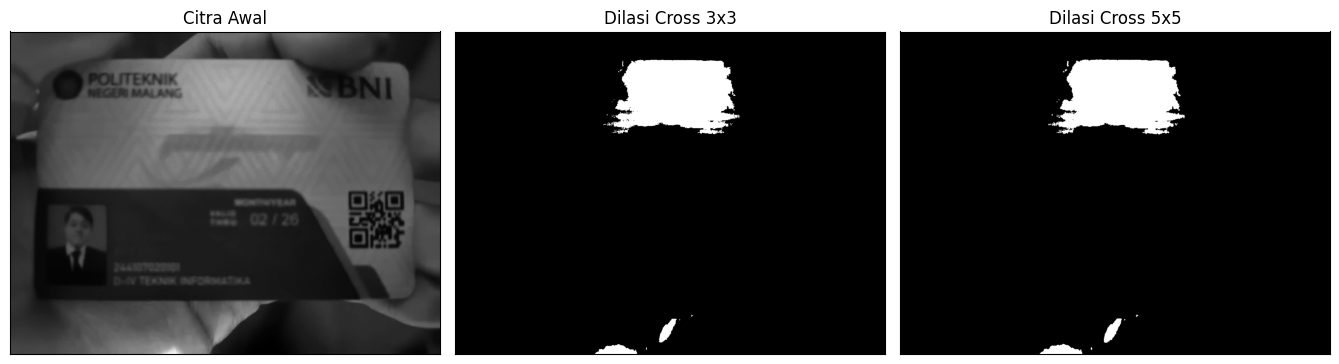

In [ ]:
SE_cross5 = np.array([[0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0],
                      [1, 1, 1, 1, 1],
                      [0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0]], dtype=np.uint8)

img_d = cv2.imread(IMG_PLAT, 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
print('SE = Cross 3'); print(SE_cross3)
print('SE = Cross 5'); print(SE_cross5)
tampil([img_d, dilasi_citra(thresh, SE_cross3), dilasi_citra(thresh, SE_cross5)],
       ['Citra Awal', 'Dilasi Cross 3x3', 'Dilasi Cross 5x5'])

## Langkah 10 — Dilasi dengan SE Circular 3x3 dan 5x5

SE = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
SE = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


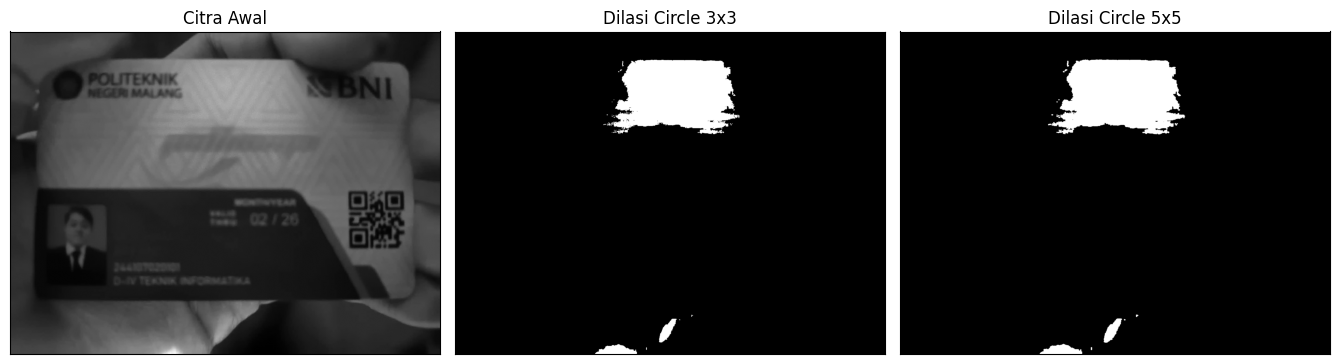

In [ ]:
SE_circ3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
SE_circ5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print('SE = Circle 3'); print(SE_circ3)
print('SE = Circle 5'); print(SE_circ5)
tampil([img_d, dilasi_citra(thresh, SE_circ3), dilasi_citra(thresh, SE_circ5)],
       ['Citra Awal', 'Dilasi Circle 3x3', 'Dilasi Circle 5x5'])

## Langkah 11 — Erosi dengan SE Rectangle 3x5 dan 5x7
\`cv2.getStructuringElement(MORPH_RECT, (p, l))\` menghasilkan matriks **l baris × p kolom**. Rectangle 3x5 berarti 3 baris × 5 kolom.

SE Rectangle 3x5 shape: (3, 5) | 5x7 shape: (5, 7)


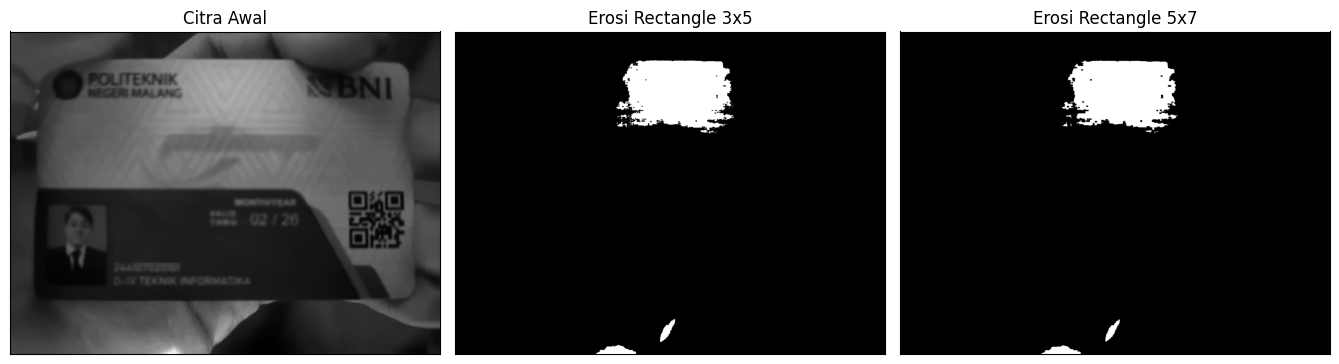

In [ ]:
img_e = cv2.imread(IMG_PLAT, 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)
SE_r35 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3))   # 3 baris x 5 kolom
SE_r57 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 5))   # 5 baris x 7 kolom
print('SE Rectangle 3x5 shape:', SE_r35.shape, '| 5x7 shape:', SE_r57.shape)
tampil([img_e, erosi_citra(thresh1, SE_r35), erosi_citra(thresh1, SE_r57)],
       ['Citra Awal', 'Erosi Rectangle 3x5', 'Erosi Rectangle 5x7'])

## Langkah 12 — Erosi dengan SE Line Vertikal 3 dan 5
Di modul, SE dibuat dengan \`(1,k)\`, tapi jendela yang dipotong berukuran k×k sehingga terjadi *broadcasting* yang keliru. Di sini SE garis vertikal dibuat eksplisit berukuran k×1.

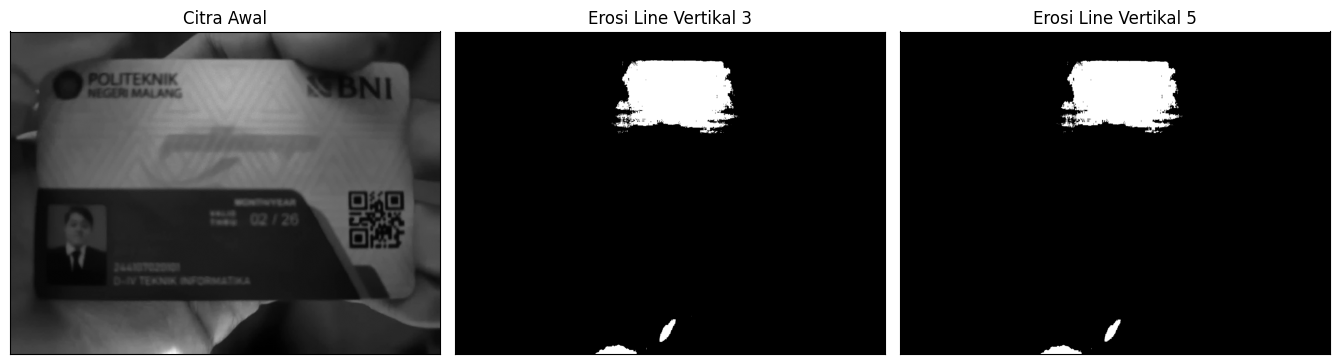

In [ ]:
SE_v3 = np.ones((3, 1), np.uint8)
SE_v5 = np.ones((5, 1), np.uint8)
tampil([img_e, erosi_citra(thresh1, SE_v3), erosi_citra(thresh1, SE_v5)],
       ['Citra Awal', 'Erosi Line Vertikal 3', 'Erosi Line Vertikal 5'])

## Langkah 13 — Top-Hat
Top-hat = citra − opening(citra). Hasilnya menonjolkan detail **terang** yang lebih kecil dari SE. (Bug modul: variabel \`input_image\` tidak didefinisikan, diganti \`img\`.)

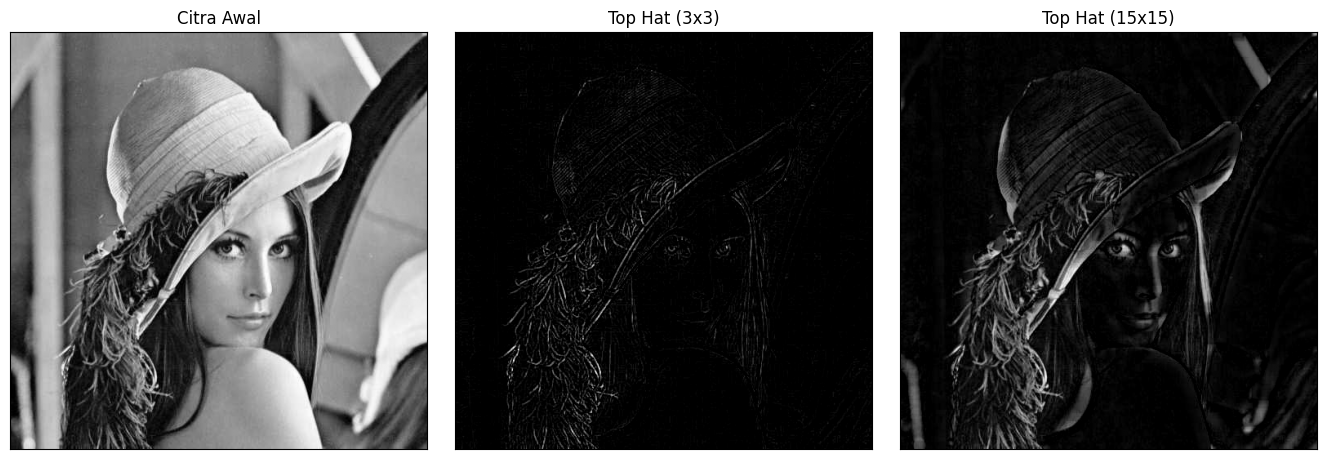

In [ ]:
img = cv2.cvtColor(cv2.imread(IMG_KITTEN), cv2.COLOR_BGR2GRAY)
kernel3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel15 = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel3)
tophat_15 = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel15)
tampil([img, tophat_img, tophat_15], ['Citra Awal', 'Top Hat (3x3)', 'Top Hat (15x15)'])

## Langkah 14 — Black-Hat
Black-hat = closing(citra) − citra. Hasilnya menonjolkan detail **gelap** yang lebih kecil dari SE.

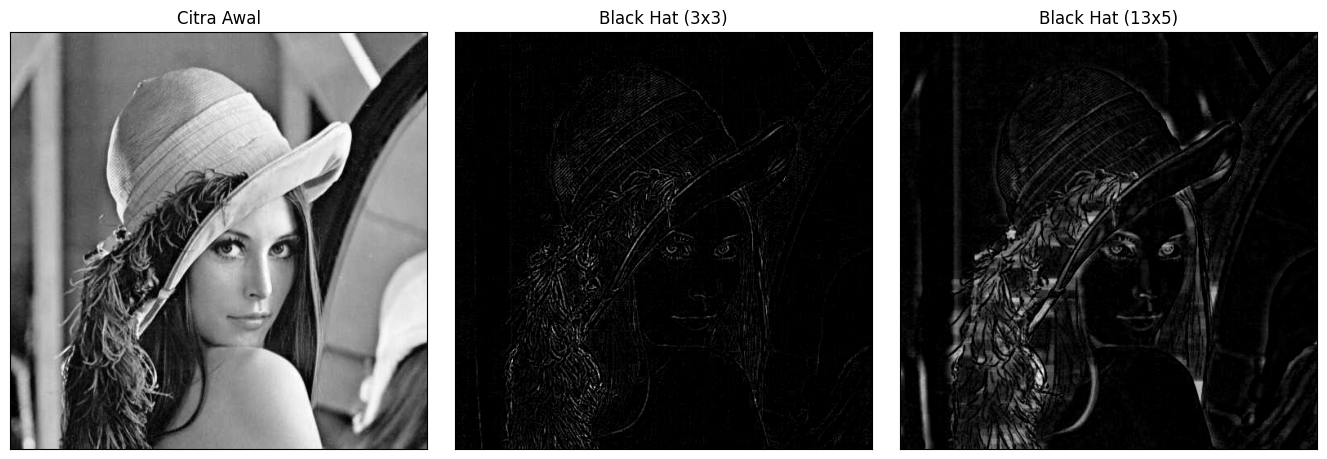

In [ ]:
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
blackhat3 = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel3)
tampil([img, blackhat3, blackhat], ['Citra Awal', 'Black Hat (3x3)', 'Black Hat (13x5)'])

## Langkah 15 — Skeleton

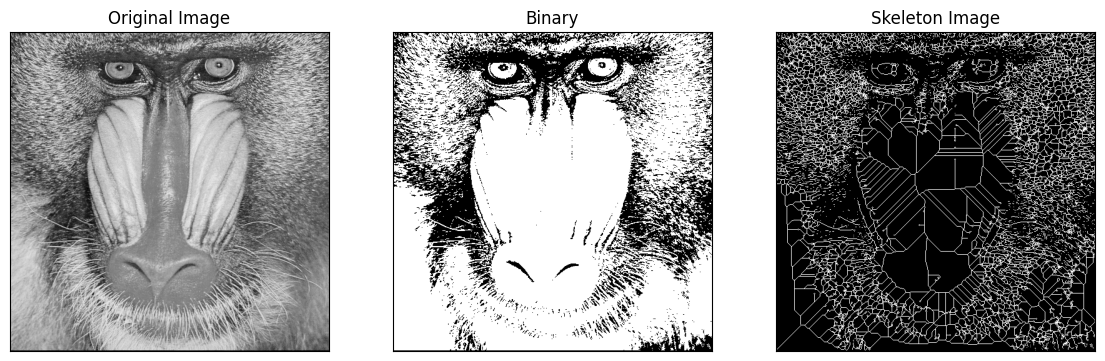

Jumlah piksel objek: 195217 | piksel skeleton: 44926


In [ ]:
from skimage import filters, io, color, morphology
from skimage.morphology import skeletonize

img_s = cv2.imread(IMG_LILY, 0)
binary = img_s > filters.threshold_triangle(img_s)
skeleton = skeletonize(binary)

plt.figure(figsize=(14, 7))
plt.subplot(131), plt.imshow(img_s, cmap='gray'), plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(binary, cmap='gray'), plt.title('Binary'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(skeleton, cmap='gray'), plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary_and_bin_skeleton.png'); plt.show()
print('Jumlah piksel objek:', binary.sum(), '| piksel skeleton:', skeleton.sum())

## Langkah 16 — Skeleton Inverse

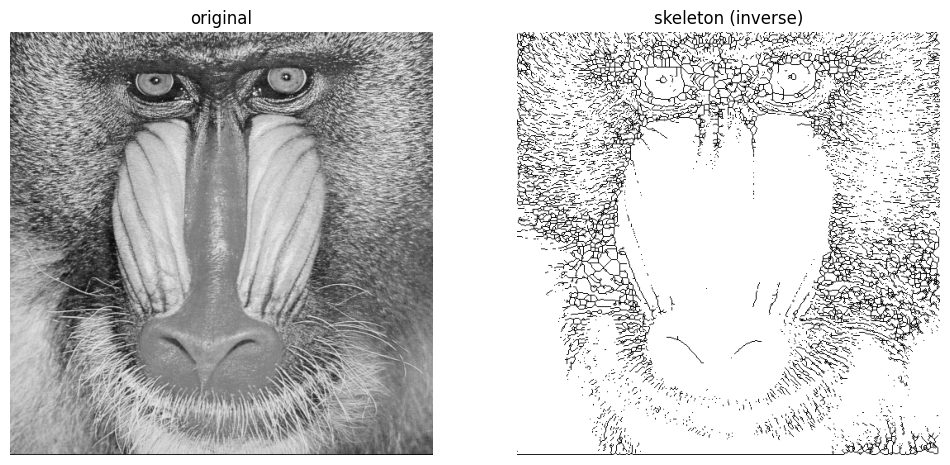

In [ ]:
binary_inv = img_s < filters.threshold_triangle(img_s)   # bagian gelap = True
skeleton_inv = skeletonize(binary_inv)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img_s, cmap='gray'); ax[0].set_title('original'); ax[0].set_axis_off()
ax[1].imshow(skeleton_inv, cmap='gray_r'); ax[1].set_title('skeleton (inverse)'); ax[1].set_axis_off()
plt.show()

## Langkah 17 — Thinning dan Thickening
Modul hanya menampilkan *thin*. Sebagai tambahan, **thickening** juga diimplementasikan memakai sifat dualitas: thickening(A) = komplemen( thinning( komplemen(A) ) ).

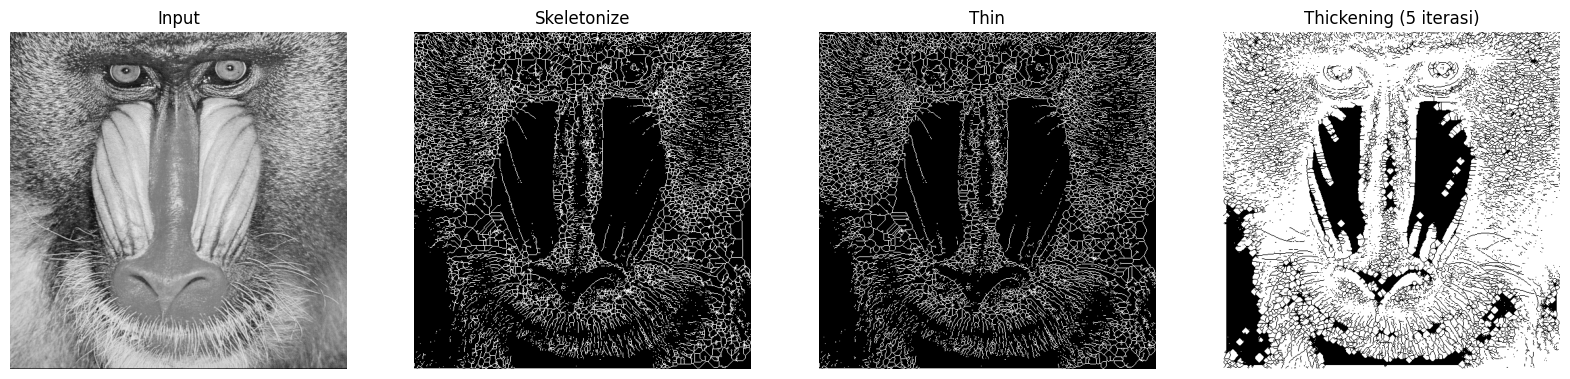

In [ ]:
from skimage import img_as_float
image = img_as_float(cv2.cvtColor(cv2.imread(IMG_LILY), cv2.COLOR_BGR2GRAY))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)
out_thick = ~morphology.thin(~image_binary, max_num_iter=5)   # thickening 5 iterasi

f, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(ax, [image, out_skeletonize, out_thin, out_thick], ['Input', 'Skeletonize', 'Thin', 'Thickening (5 iterasi)']):
    a.imshow(im, cmap='gray'); a.set_title(t); a.set_axis_off()
plt.savefig('/tmp/char_out.png'); plt.show()

---
# E. Tugas Praktikum — Morfologi pada Citra KTP
**Tujuan:** membuat teks KTP lebih mudah dibaca dengan teknik morfologi.

**Pipeline:**
1. Resize ke lebar 1000 px, ubah ke grayscale, lalu CLAHE untuk meratakan kontras.
2. **Black-hat** (SE rectangle) untuk menonjolkan teks gelap di atas latar KTP yang terang, sekaligus menekan pola/gradasi latar.
3. Threshold **Otsu** untuk membuat citra biner teks.
4. **Opening** kecil untuk membuang bintik noise.
5. **Closing horizontal + dilasi** untuk menyatukan huruf menjadi blok baris, lalu kontur menjadi *bounding box* area teks.
6. Citra bersih (teks hitam, latar putih) dibandingkan hasil OCR-nya (Tesseract) antara sebelum dan sesudah morfologi.

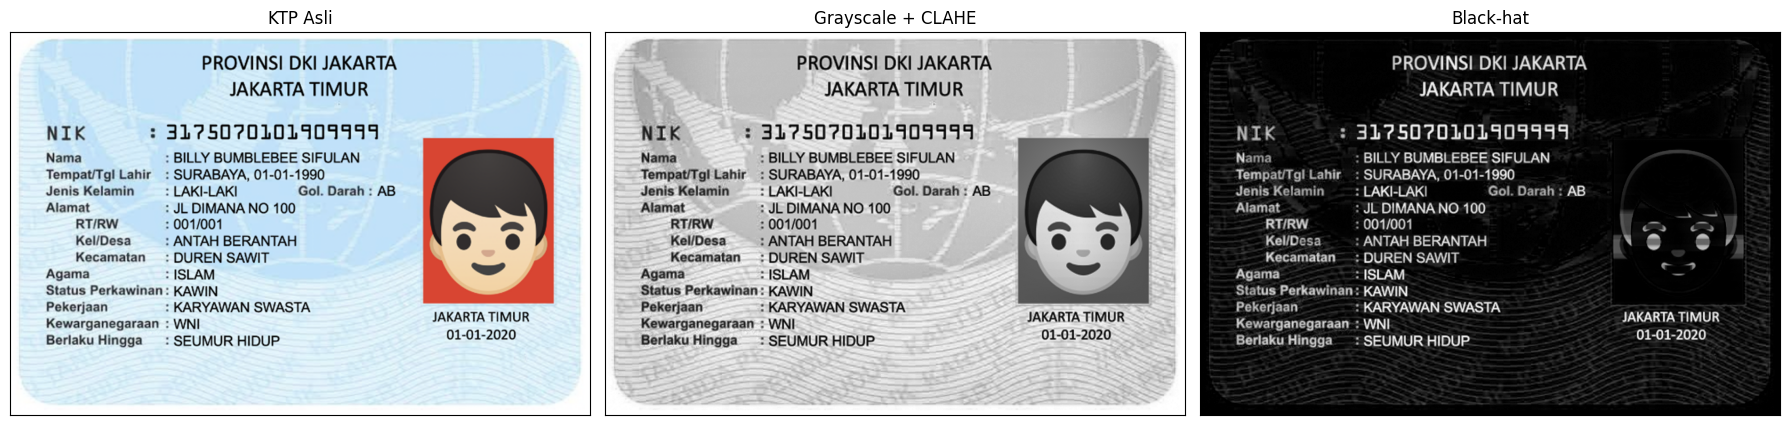

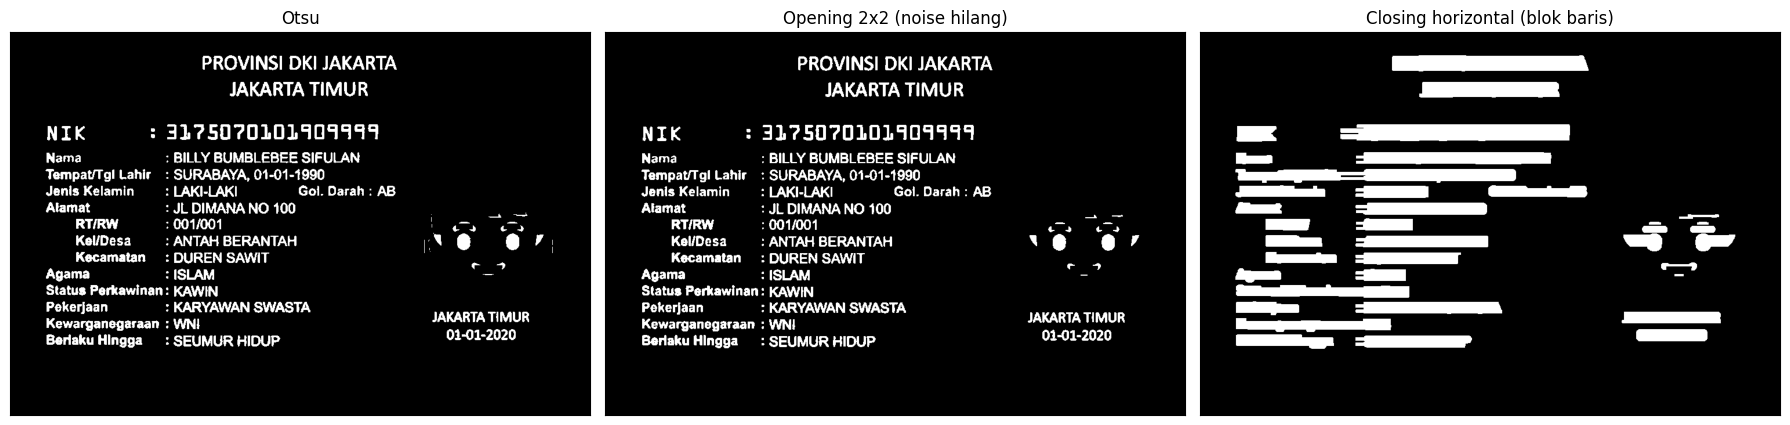

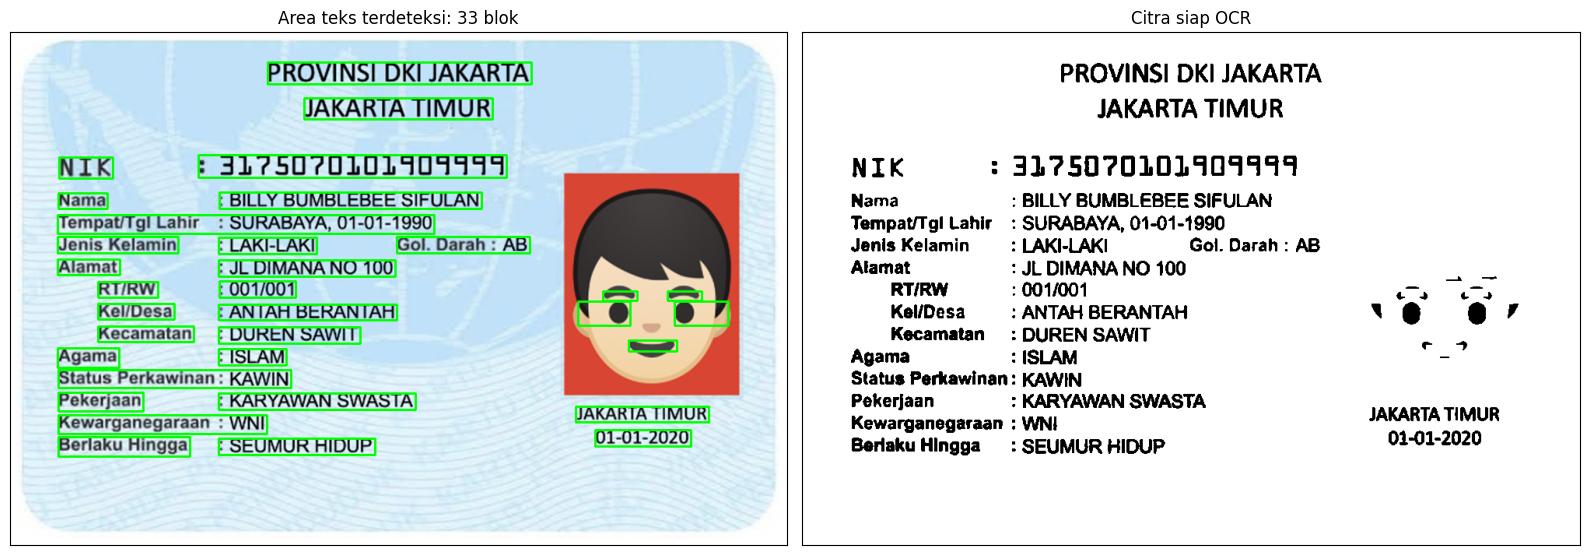

In [ ]:
def proses_ktp(path, lebar=1000, k_bh=(25, 9), k_line=(35, 3)):
    src = cv2.imread(path)
    s = lebar / src.shape[1]
    src = cv2.resize(src, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)
    gray_eq = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)

    # 1) Black-hat: teks gelap -> terang, latar ditekan
    bh = cv2.morphologyEx(gray_eq, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, k_bh))
    # 2) Otsu
    _, biner = cv2.threshold(bh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # 3) Opening: buang noise titik
    bersih = cv2.morphologyEx(biner, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2)))
    # 4) Closing horizontal + dilasi: gabung huruf jadi baris
    baris = cv2.morphologyEx(bersih, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, k_line))
    baris = cv2.dilate(baris, cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3)))
    # 5) Kontur -> bounding box teks
    cnts, _ = cv2.findContours(baris, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    vis, boxes = src.copy(), []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        if w > 20 and 8 < h < 70 and w / h > 1.2:
            boxes.append((x, y, w, h))
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    ocr_ready = 255 - bersih   # teks hitam di atas putih
    return dict(src=src, gray=gray, gray_eq=gray_eq, blackhat=bh, biner=biner,
                bersih=bersih, baris=baris, vis=vis, boxes=sorted(boxes, key=lambda b: (b[1], b[0])),
                ocr_ready=ocr_ready)

R = proses_ktp(IMG_KTP)
tampil([R['src'], R['gray_eq'], R['blackhat']], ['KTP Asli', 'Grayscale + CLAHE', 'Black-hat'], size=6)
tampil([R['biner'], R['bersih'], R['baris']], ['Otsu', 'Opening 2x2 (noise hilang)', 'Closing horizontal (blok baris)'], size=6)
tampil([R['vis'], R['ocr_ready']], [f'Area teks terdeteksi: {len(R["boxes"])} blok', 'Citra siap OCR'], size=8)

### Uji keterbacaan dengan OCR (Tesseract, bahasa Indonesia)
Membandingkan teks yang terbaca dari grayscale asli dan dari citra hasil morfologi.

In [ ]:
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind > /dev/null
!pip -q install pytesseract
import pytesseract

cfg = '--oem 3 --psm 6'
for nama, im in [('GRAYSCALE ASLI', R['gray']), ('SETELAH MORFOLOGI', R['ocr_ready'])]:
    txt = pytesseract.image_to_string(im, lang='ind', config=cfg).strip()
    print('=' * 25, nama, '=' * 25)
    print(txt[:1200], '\n')

========================= GRAYSCALE ASLI =========================
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?50?01014041417
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020 

========================= SETELAH MORFOLOGI =========================
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK : 3175070101409441
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin 1 LAKI-LAKI Gol. Darah : AB
Alamat 1 JL DIMANA NO 100 A.A —
RT/RW : 001/001 ta
KeliDesa : ANTAH BERANTAH 1“ @”r
Kecamatan : DUREN SAWIT c 3
Agama : ISLAM -
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020 



### Bonus — pipeline yang sama pada citra KTM (Modul 7)

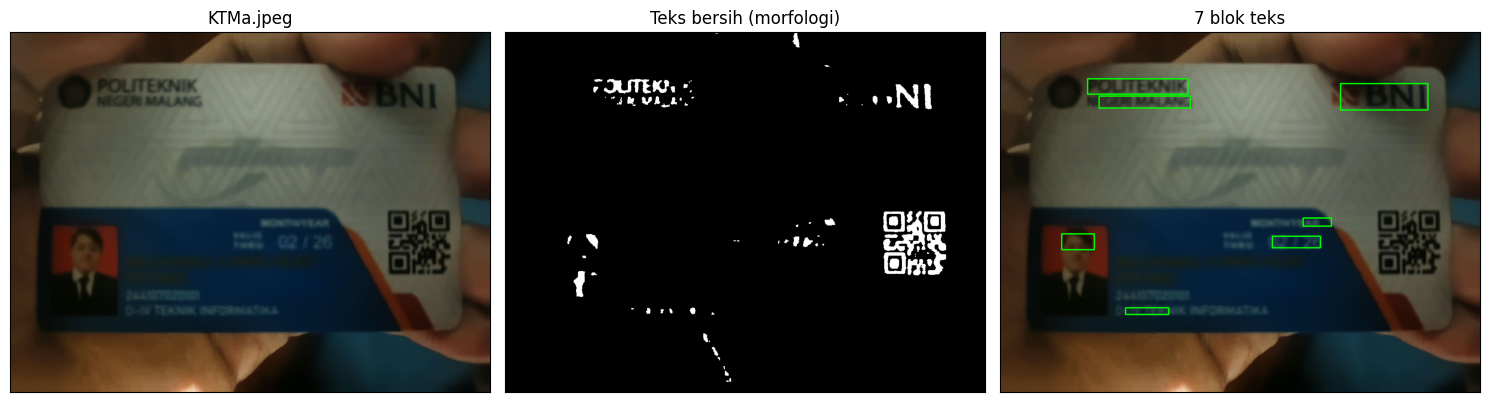

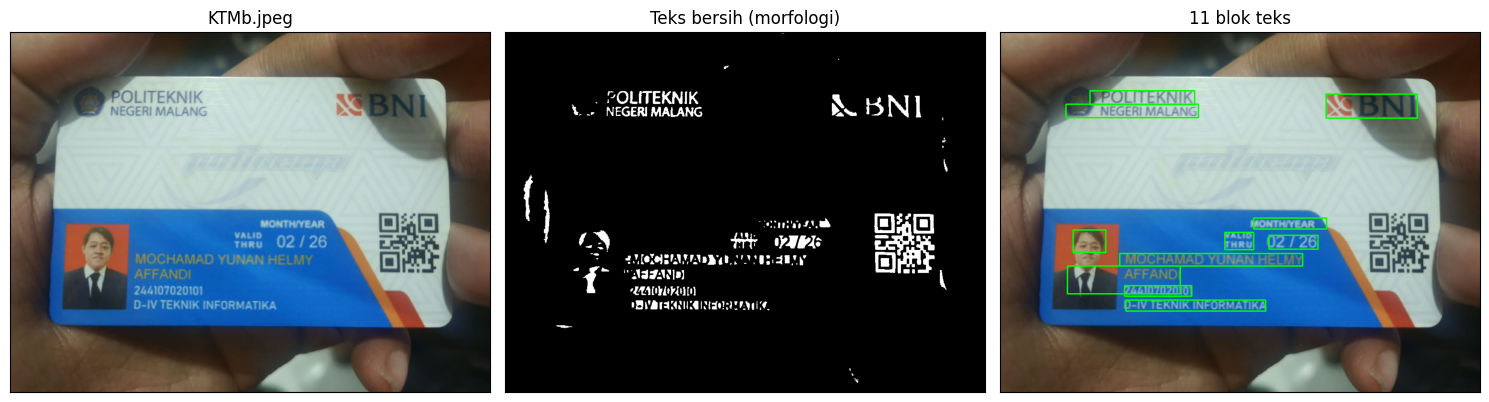

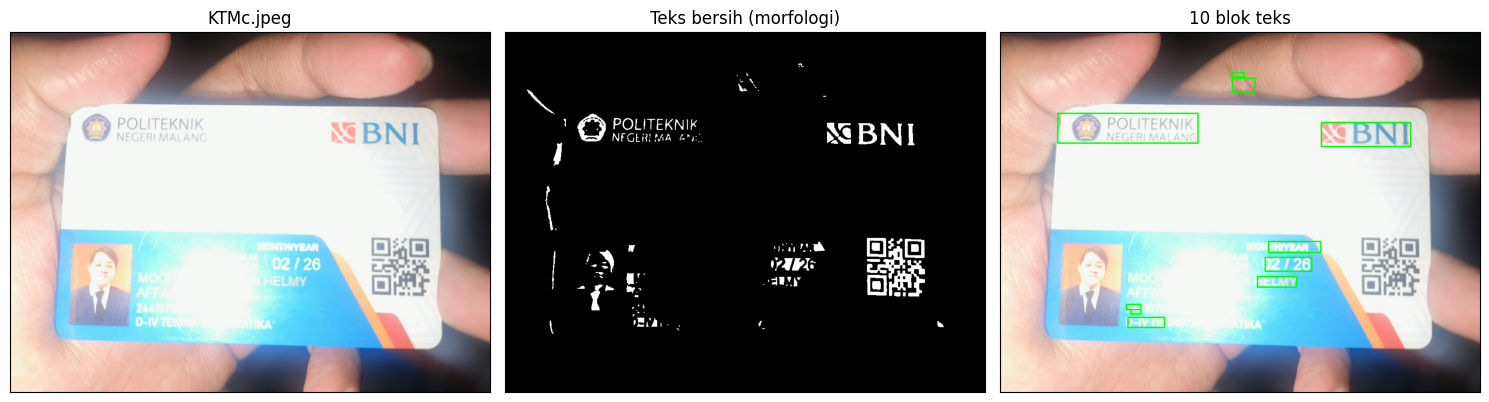

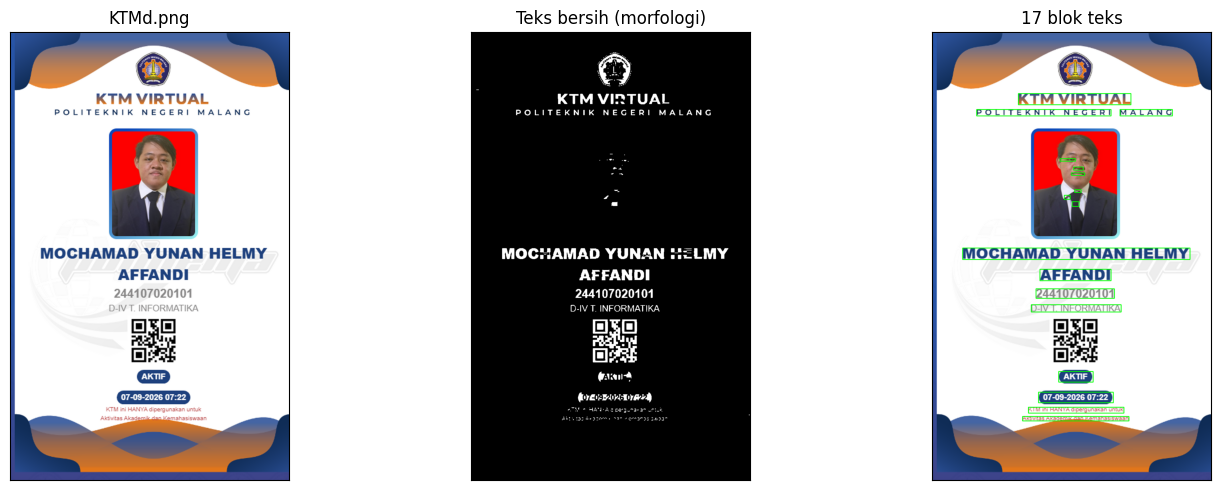

In [ ]:
ktm = [p for p in ['KTMa.jpeg', 'KTMb.jpeg', 'KTMc.jpeg', 'KTMd.png'] if os.path.exists(os.path.join(BASE, p))]
for p in ktm:
    r = proses_ktp(os.path.join(BASE, p))
    tampil([r['src'], r['bersih'], r['vis']], [p, 'Teks bersih (morfologi)', f'{len(r["boxes"])} blok teks'], size=5)

## Kesimpulan
- **Erosi** menipiskan objek dan menghapus objek kecil. Makin besar SE, makin banyak bagian huruf yang hilang (terlihat pada square 5x5 dan rectangle 5x7).
- **Dilasi** menebalkan objek dan menyambung bagian yang terputus. SE cross menebal ke arah vertikal/horizontal, SE circle menebal lebih merata.
- **Opening** (erosi → dilasi) membuang noise terang kecil, sedangkan **closing** (dilasi → erosi) menutup lubang dan celah kecil. Dengan SE 3x3 bentuk huruf utama tetap terjaga; dengan k=7 objek tipis ikut hilang (opening) atau menggumpal (closing).
- **Top-hat** mengambil detail terang kecil, **black-hat** mengambil detail gelap kecil. Black-hat inilah kunci tugas KTP karena teks KTP gelap di atas latar terang.
- **Skeleton/thinning** mereduksi objek menjadi rangka 1 piksel. **Thickening** adalah dual-nya.
- Fungsi manual terbukti **identik** dengan \`cv2.dilate/erode/morphologyEx\` (output \`True\` pada verifikasi). Bug pada modul (erosi SE non-persegi, SE line, \`input_image\`, nilai maks threshold 225) sudah diperbaiki.
- Pada **KTP**, kombinasi CLAHE → black-hat → Otsu → opening → closing berhasil menghilangkan pola latar dan melokalisasi baris teks. Hasil OCR menunjukkan peningkatan paling jelas pada **NIK**: dari grayscale asli terbaca \`31?50?01014041417\` (ada karakter "?" dan jumlah digit salah), sedangkan setelah morfologi terbaca **16 digit bersih** tanpa simbol aneh. Label "Status Perkawinan :" juga terbaca lebih rapi.
- **Keterbatasan:** di area foto dan tanda tangan, black-hat ikut mengangkat tepi-tepi gelap sehingga muncul karakter sampah (misalnya "ta", "@") di ujung beberapa baris. Perbaikan lanjutan: crop atau masking area foto (sisi kanan KTP) sebelum OCR, atau OCR per *bounding box* hasil deteksi baris.